# Trabajo Práctico N.º 4: Repositorios e Indexadores

**Alumno:** Aramayo Pedro Mauricio Leandro, 3.er año de Ciencias de Datos e IA
**Unidad 2:** Repositorios - Indexadores

Este cuaderno tiene tres partes y se ejecuta de arriba hacia abajo (**Entorno de ejecución → Ejecutar todas**):

1. **Consultas OAI-PMH**: los seis verbos del protocolo sobre el repositorio CORA.
2. **Recolección de CORA**: una rutina en Python que descarga 100 registros y arma un CSV.
3. **Indexador local con Apache Lucene**: indexa 100 documentos (`.doc`, `.docx`, `.pdf`, `.txt` y `.html`) y permite buscar en ellos.

## 0. Preparación del entorno

Instala lo que no viene en Colab:
- **Java** y **JPype**, para usar Apache Lucene (escrito en Java) desde Python.
- **antiword**, para leer archivos `.doc` (Word 97-2003).
- **python-docx** y **pypdf**, para leer `.docx` y `.pdf`.

Tarda alrededor de un minuto la primera vez.

In [ ]:
import shutil, subprocess, sys

paquetes_sistema = []
if shutil.which("java") is None:
    paquetes_sistema.append("default-jre-headless")
if shutil.which("antiword") is None:
    paquetes_sistema.append("antiword")
if paquetes_sistema:
    print("Instalando:", ", ".join(paquetes_sistema))
    subprocess.run(["apt-get", "-qq", "update"], check=True, stdout=subprocess.DEVNULL)
    subprocess.run(["apt-get", "-qq", "install", "-y", *paquetes_sistema], check=True, stdout=subprocess.DEVNULL)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "JPype1", "python-docx", "pypdf"], check=True)
print("Listo:", subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])

## Parte 1. Consultas OAI-PMH

**Documentación oficial usada como referencia:** [The Open Archives Initiative Protocol for Metadata Harvesting, versión 2.0](https://www.openarchives.org/OAI/openarchivesprotocol.html)

OAI-PMH es un protocolo para pedirle metadatos a un repositorio con URLs simples. Cada consulta lleva un **verbo** (`verb`) y el repositorio responde en XML.

**Repositorio elegido:** CORA. Repositori de Dades de Recerca (Cataluña), basado en Dataverse.
Tiene más de 4.000 registros (lo muestra el atributo `completeListSize` en `ListRecords`), así que cumple con el mínimo de 100.

**URL base OAI-PMH:** `https://dataverse.csuc.cat/oai`

Para cada verbo se muestra: la URL exacta, la captura real tomada en el navegador (Chrome, 25/11/2026) y la misma consulta ejecutada en vivo desde el cuaderno.

In [ ]:
import requests
import xml.etree.ElementTree as ET
from xml.dom import minidom

URL_BASE = "https://dataverse.csuc.cat/oai"
NS = {
    "oai": "http://www.openarchives.org/OAI/2.0/",
    "oai_dc": "http://www.openarchives.org/OAI/2.0/oai_dc/",
    "dc": "http://purl.org/dc/elements/1.1/",
}

ultimo_xml = b""  # texto de la última respuesta, para mostrarlo tal cual llegó

def consultar(**parametros):
    """Arma la URL de la consulta, la ejecuta y devuelve el XML interpretado."""
    global ultimo_xml
    url = URL_BASE + "?" + "&".join(f"{clave}={valor}" for clave, valor in parametros.items())
    print("URL:", url)
    respuesta = requests.get(url, timeout=60)
    respuesta.raise_for_status()
    ultimo_xml = respuesta.content
    return ET.fromstring(respuesta.content)

def mostrar_inicio(lineas=12):
    """Muestra las primeras líneas de la última respuesta XML con sangría, como se ve en el navegador."""
    texto = minidom.parseString(ultimo_xml).toprettyxml(indent="  ")
    print("\n".join(texto.splitlines()[1:lineas + 1]))
    print("  ...")

### 1.1 `Identify`

**URL:** [https://dataverse.csuc.cat/oai?verb=Identify](https://dataverse.csuc.cat/oai?verb=Identify)

**Qué devuelve:** `Identify` devuelve la ficha del repositorio: su nombre, la URL base, la versión del protocolo, el correo del administrador y la fecha del registro más antiguo.

**Captura del resultado:**

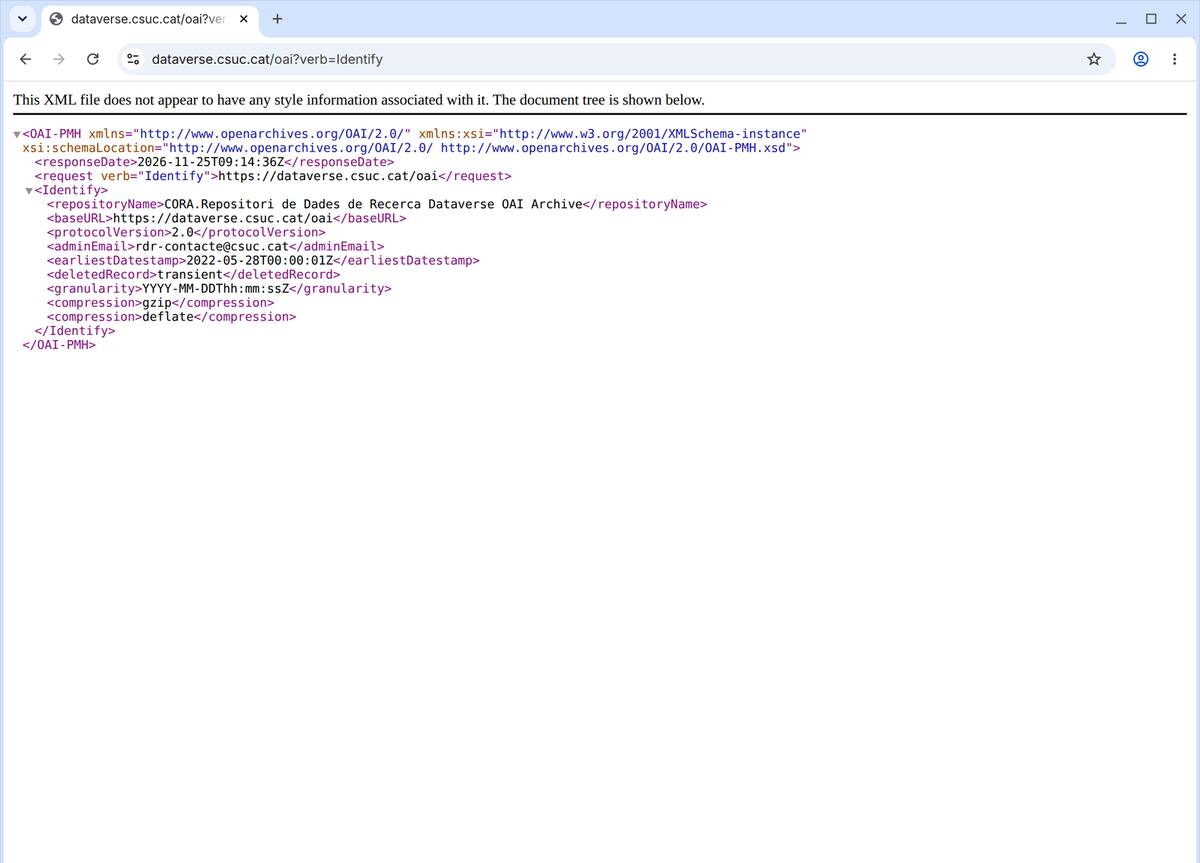

In [ ]:
raiz = consultar(verb="Identify")
info = raiz.find("oai:Identify", NS)
for campo in ["repositoryName", "baseURL", "protocolVersion", "adminEmail", "earliestDatestamp"]:
    print(f"{campo}: {info.find('oai:' + campo, NS).text}")

print()
mostrar_inicio()

### 1.2 `ListMetadataFormats`

**URL:** [https://dataverse.csuc.cat/oai?verb=ListMetadataFormats](https://dataverse.csuc.cat/oai?verb=ListMetadataFormats)

**Qué devuelve:** `ListMetadataFormats` devuelve los formatos de metadatos que ofrece el repositorio; entre ellos está `oai_dc` (Dublin Core), que usamos en el resto del trabajo.

**Captura del resultado:**

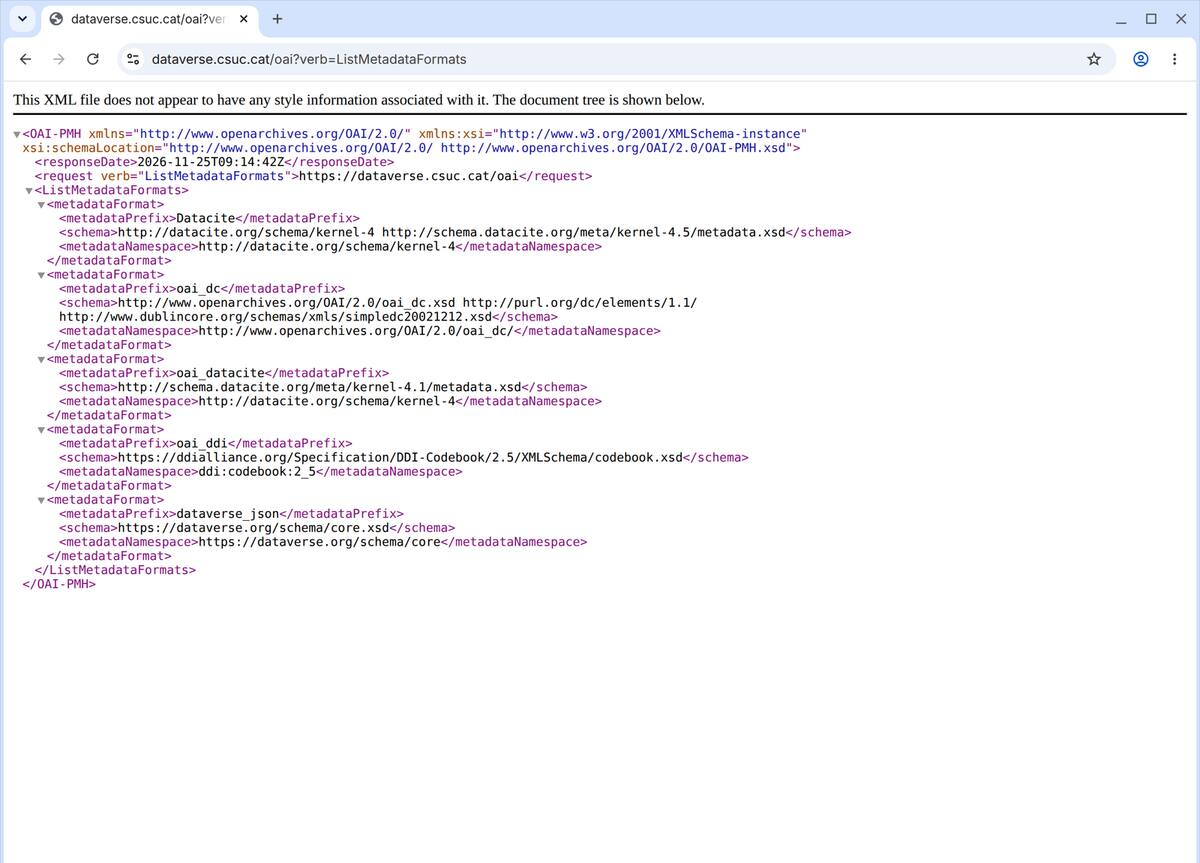

In [ ]:
raiz = consultar(verb="ListMetadataFormats")
formatos = [f.text for f in raiz.iter("{http://www.openarchives.org/OAI/2.0/}metadataPrefix")]
print("Formatos disponibles:", ", ".join(formatos))

print()
mostrar_inicio()

### 1.3 `ListSets`

**URL:** [https://dataverse.csuc.cat/oai?verb=ListSets](https://dataverse.csuc.cat/oai?verb=ListSets)

**Qué devuelve:** `ListSets` devuelve los conjuntos (*sets*) en que se agrupan los registros; en CORA cada set es una institución o colección (por ejemplo, UB, UPC o CREAF).

**Captura del resultado:**

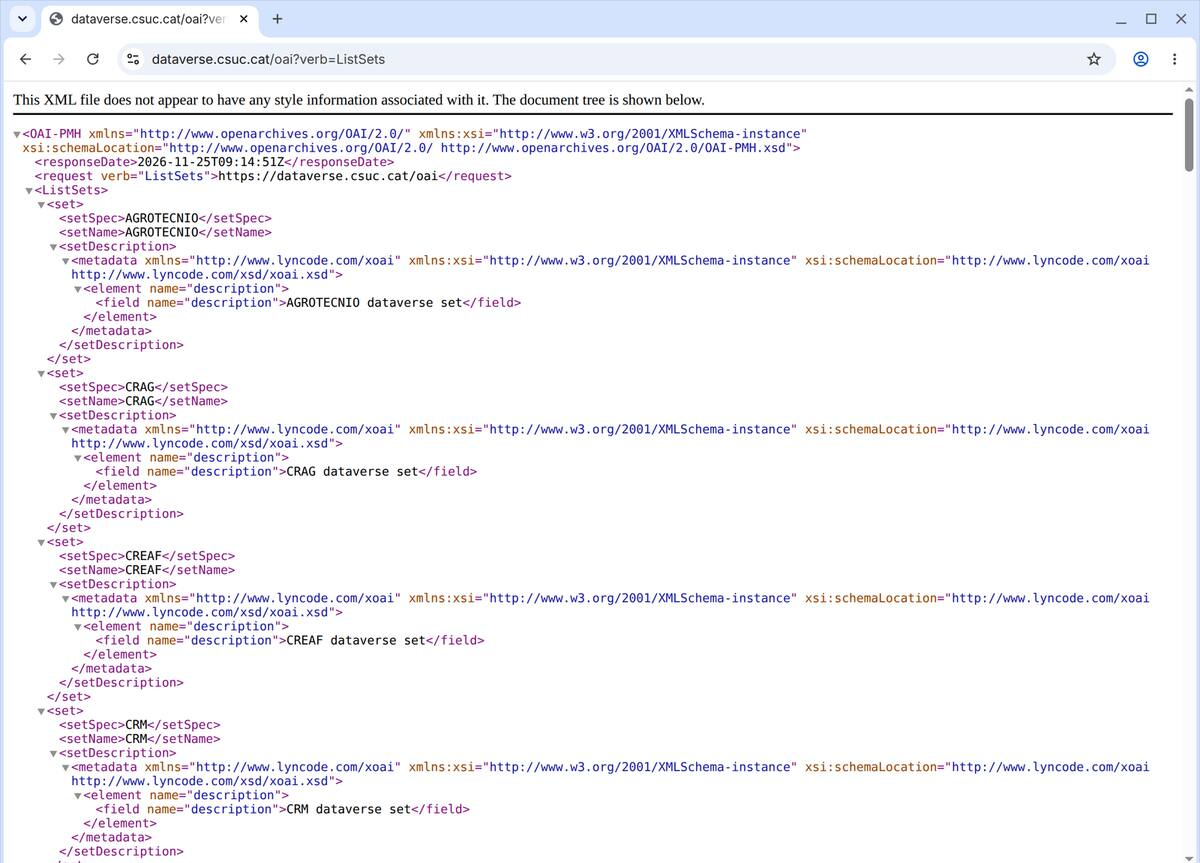

In [ ]:
raiz = consultar(verb="ListSets")
sets = raiz.findall("oai:ListSets/oai:set", NS)
print(f"Sets en esta respuesta: {len(sets)}")
print("Primeros sets:", ", ".join(s.find("oai:setSpec", NS).text for s in sets[:12]))

print()
mostrar_inicio()

### 1.4 `ListIdentifiers`

**URL:** [https://dataverse.csuc.cat/oai?verb=ListIdentifiers&metadataPrefix=oai_dc](https://dataverse.csuc.cat/oai?verb=ListIdentifiers&metadataPrefix=oai_dc)

**Qué devuelve:** `ListIdentifiers` devuelve solo las cabeceras de los registros (identificador, fecha y sets), sin los metadatos; las marcadas con `status="deleted"` son registros borrados.

**Captura del resultado:**

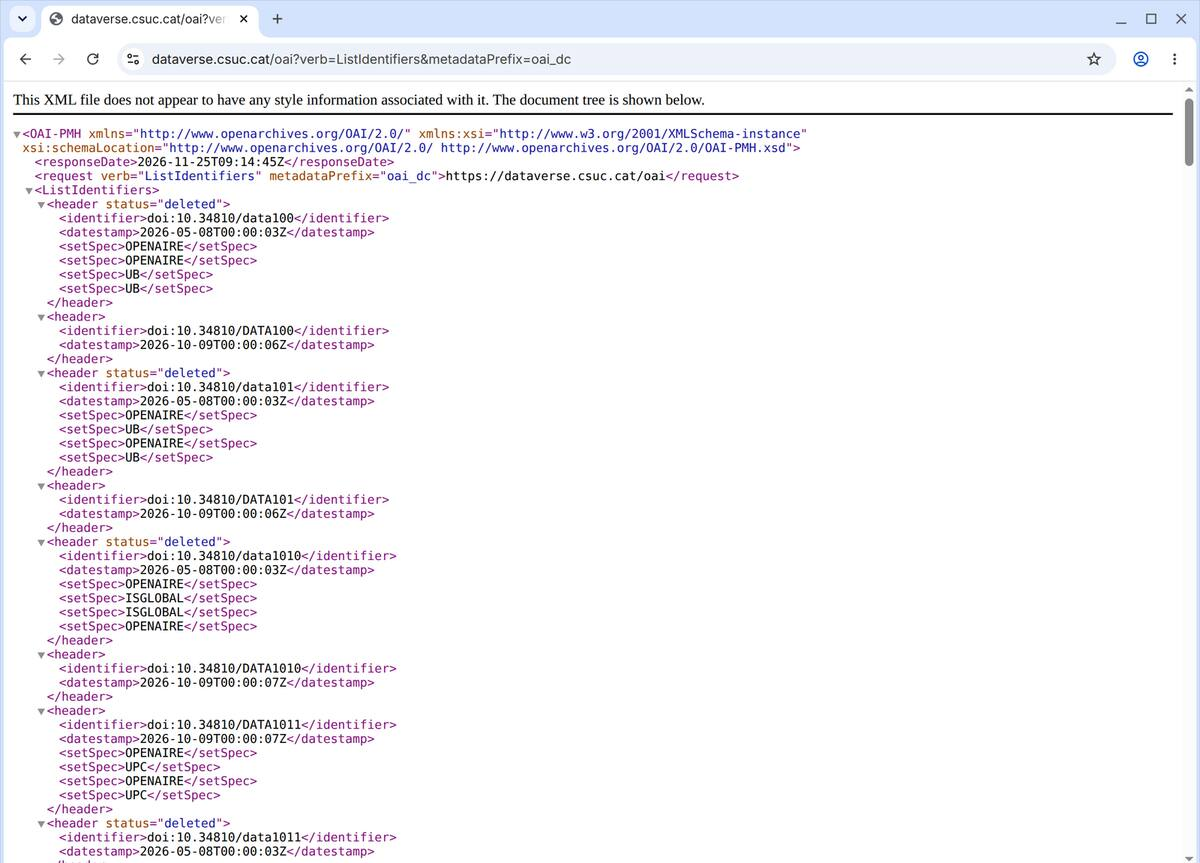

In [ ]:
raiz = consultar(verb="ListIdentifiers", metadataPrefix="oai_dc")
cabeceras = raiz.findall("oai:ListIdentifiers/oai:header", NS)
activos = [c.find("oai:identifier", NS).text for c in cabeceras if c.get("status") != "deleted"]
token = raiz.find("oai:ListIdentifiers/oai:resumptionToken", NS)
print(f"Cabeceras en esta página: {len(cabeceras)} ({len(activos)} activas)")
print("Tamaño total informado (completeListSize):", token.get("completeListSize"))
print("Primeros identificadores activos:", activos[:5])

print()
mostrar_inicio()

### 1.5 `GetRecord`

**URL:** [https://dataverse.csuc.cat/oai?verb=GetRecord&identifier=doi:10.34810/DATA101&metadataPrefix=oai_dc](https://dataverse.csuc.cat/oai?verb=GetRecord&identifier=doi:10.34810/DATA101&metadataPrefix=oai_dc)

**Qué devuelve:** `GetRecord` devuelve un único registro completo, con su cabecera y todos sus metadatos Dublin Core (título, autores, fecha, descripción, temas, etc.).

El identificador `doi:10.34810/DATA101` sale de la consulta `ListIdentifiers` anterior. (El primero de la lista, `DATA100`, coincide con una versión borrada y el repositorio lo devuelve como `deleted`; por eso se toma el siguiente.)

**Captura del resultado:**

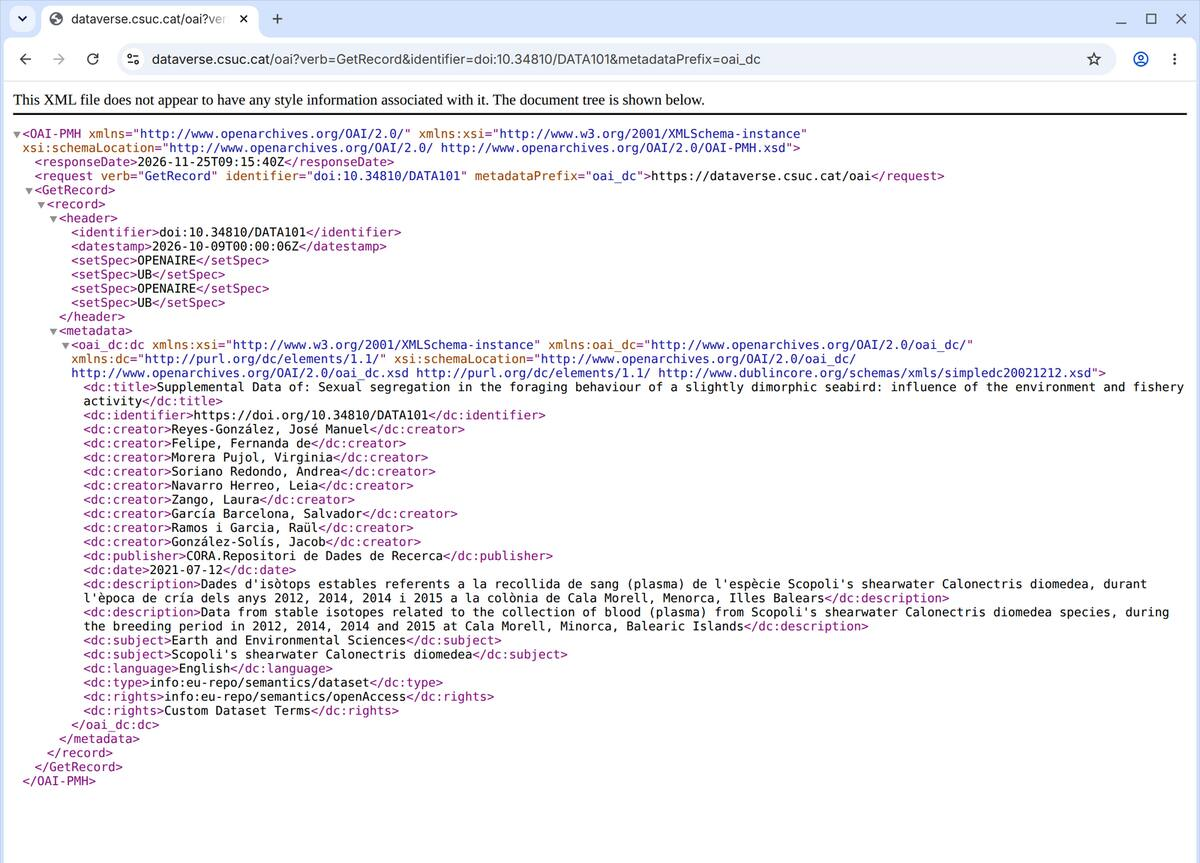

In [ ]:
# Se usa un identificador obtenido con ListIdentifiers (celda anterior).
# Si el repositorio responde ese identificador como borrado, se prueba con el siguiente.
for identificador in activos:
    raiz = consultar(verb="GetRecord", identifier=identificador, metadataPrefix="oai_dc")
    dc = raiz.find("oai:GetRecord/oai:record/oai:metadata/oai_dc:dc", NS)
    if dc is not None:
        break
    print("  -> figura como borrado, pruebo el siguiente identificador")

print("Identificador:", identificador)
print("Título:", dc.find("dc:title", NS).text)
print("Autores:", "; ".join(a.text for a in dc.findall("dc:creator", NS)))
print("Fecha:", dc.find("dc:date", NS).text)

print()
mostrar_inicio()

### 1.6 `ListRecords`

**URL:** [https://dataverse.csuc.cat/oai?verb=ListRecords&metadataPrefix=oai_dc](https://dataverse.csuc.cat/oai?verb=ListRecords&metadataPrefix=oai_dc)

**Qué devuelve:** `ListRecords` devuelve una página de registros completos (cabecera + metadatos) y, al final, un `resumptionToken` para pedir la página siguiente.

**Captura del resultado:**

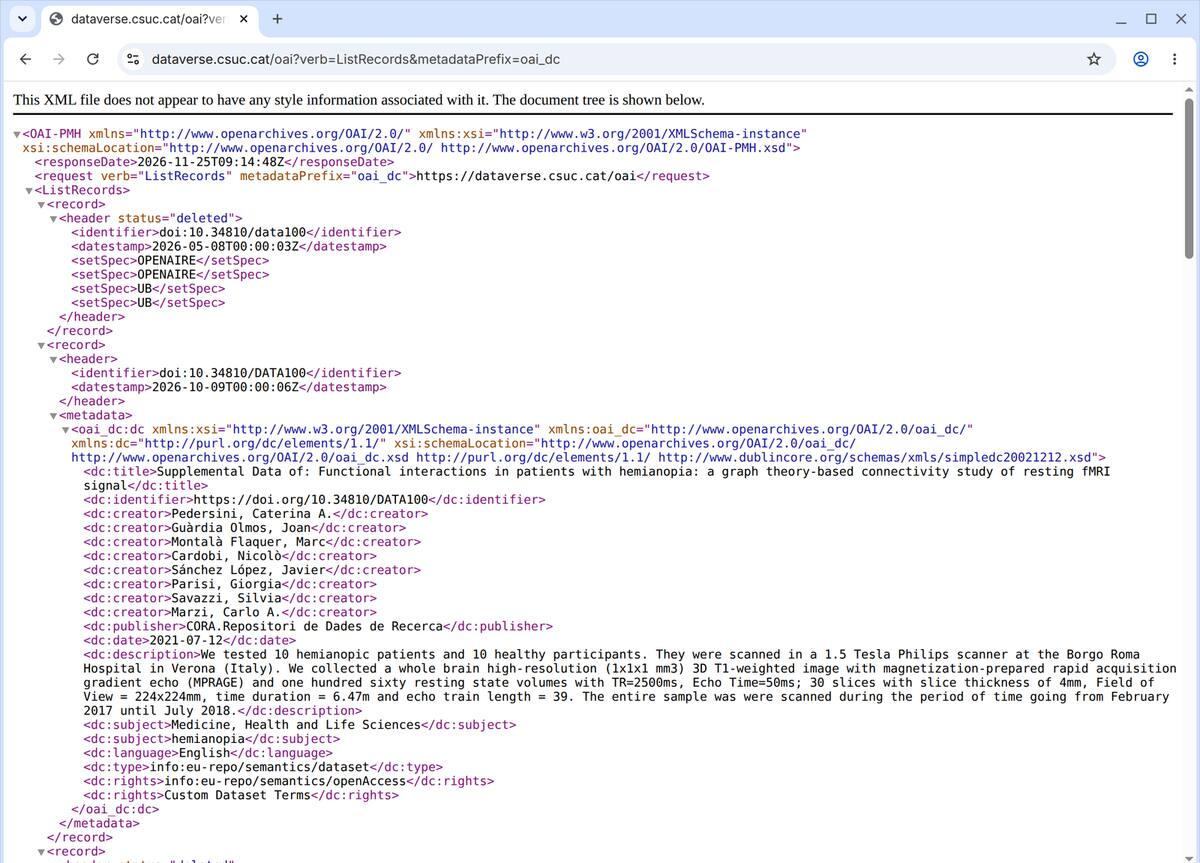

In [ ]:
raiz = consultar(verb="ListRecords", metadataPrefix="oai_dc")
registros = raiz.findall("oai:ListRecords/oai:record", NS)
token = raiz.find("oai:ListRecords/oai:resumptionToken", NS)
print(f"Registros en esta página: {len(registros)}")
print("Total de registros del repositorio (completeListSize):", token.get("completeListSize"))
print("resumptionToken para la página siguiente:", token.text)

print()
mostrar_inicio()

## Parte 2. Recolección de registros de CORA

La rutina pide páginas con `ListRecords` (formato `oai_dc`) a `https://dataverse.csuc.cat/oai`:

1. Lee los registros de la página y **saltea los borrados** (`status="deleted"`) y los repetidos.
2. Si todavía no llegó a 100, toma el `resumptionToken` y pide la página siguiente.
3. Guarda los registros **completos** (cabecera + todos los metadatos) en `resultados/cora_registros.xml`.
4. Arma `resultados/cora_registros.csv` con **título, resumen, autores, palabras clave y fecha**. Cuando hay varios autores o palabras clave, se guardan todos en la misma celda separados por ` | `.

Esta misma rutina está en el archivo `recoleccion_cora.py` de la entrega.

In [ ]:
"""
Recolección OAI-PMH del repositorio CORA (Repositori de Dades de Recerca).
Autor: Aramayo Pedro Mauricio Leandro - 3.er año, Ciencias de Datos e IA.

Descarga al menos 100 registros distintos con el verbo ListRecords (formato oai_dc),
sigue el resumptionToken para pasar de página, guarda los registros completos en XML
y arma un CSV con título, resumen, autores, palabras clave y fecha.
"""
import csv
import time
import xml.etree.ElementTree as ET

import requests

URL_BASE = "https://dataverse.csuc.cat/oai"
CANTIDAD_MINIMA = 100
ARCHIVO_XML = "cora_registros.xml"
ARCHIVO_CSV = "cora_registros.csv"
SEPARADOR = " | "  # separa varios autores o varias palabras clave en una misma celda

NS = {
    "oai": "http://www.openarchives.org/OAI/2.0/",
    "oai_dc": "http://www.openarchives.org/OAI/2.0/oai_dc/",
    "dc": "http://purl.org/dc/elements/1.1/",
}
for prefijo, uri in NS.items():
    ET.register_namespace(prefijo, uri)
ET.register_namespace("xsi", "http://www.w3.org/2001/XMLSchema-instance")


def pedir_pagina(parametros, intentos=3):
    """Hace una consulta OAI-PMH y devuelve el XML ya interpretado."""
    for intento in range(1, intentos + 1):
        try:
            respuesta = requests.get(URL_BASE, params=parametros, timeout=60)
            respuesta.raise_for_status()
            return ET.fromstring(respuesta.content)
        except (requests.RequestException, ET.ParseError) as error:
            if intento == intentos:
                raise
            print(f"  Error ({error}); reintento {intento} de {intentos - 1}...")
            time.sleep(3 * intento)


def valores(metadatos, campo):
    """Devuelve todos los valores de un campo Dublin Core (ej.: todos los dc:creator)."""
    return [e.text.strip() for e in metadatos.findall(f"dc:{campo}", NS) if e.text and e.text.strip()]


def recolectar(cantidad_minima=CANTIDAD_MINIMA):
    """Recorre ListRecords página por página hasta juntar la cantidad pedida."""
    registros = []          # elementos <record> completos
    vistos = set()          # identificadores ya guardados (para no repetir)
    parametros = {"verb": "ListRecords", "metadataPrefix": "oai_dc"}
    pagina = 0

    while len(registros) < cantidad_minima:
        pagina += 1
        raiz = pedir_pagina(parametros)
        error = raiz.find("oai:error", NS)
        if error is not None:
            raise RuntimeError(f"El repositorio respondió un error: {error.get('code')} - {error.text}")

        lista = raiz.find("oai:ListRecords", NS)
        for registro in lista.findall("oai:record", NS):
            cabecera = registro.find("oai:header", NS)
            identificador = cabecera.find("oai:identifier", NS).text
            # Los registros borrados vienen sin metadatos: se saltean.
            if cabecera.get("status") == "deleted" or identificador in vistos:
                continue
            vistos.add(identificador)
            registros.append(registro)

        token = lista.find("oai:resumptionToken", NS)
        print(f"Página {pagina}: llevo {len(registros)} registros distintos")
        if token is None or not (token.text or "").strip():
            print("No hay más páginas en el repositorio.")
            break
        # Para la página siguiente solo se envía el verbo y el resumptionToken.
        parametros = {"verb": "ListRecords", "resumptionToken": token.text.strip()}
        time.sleep(0.5)  # pausa corta para no saturar el servidor

    return registros[:cantidad_minima]


def guardar_xml(registros, archivo=ARCHIVO_XML):
    """Guarda los <record> completos (cabecera + todos los metadatos) en un solo XML."""
    raiz = ET.Element("registros", {"origen": URL_BASE, "cantidad": str(len(registros))})
    raiz.extend(registros)
    ET.indent(raiz)
    ET.ElementTree(raiz).write(archivo, encoding="utf-8", xml_declaration=True)


def registro_a_fila(registro):
    """Convierte un <record> en una fila del CSV con los cinco campos pedidos."""
    identificador = registro.find("oai:header/oai:identifier", NS).text
    dc = registro.find("oai:metadata/oai_dc:dc", NS)
    return {
        "identificador": identificador,
        "titulo": SEPARADOR.join(valores(dc, "title")),
        "resumen": SEPARADOR.join(valores(dc, "description")),
        "autores": SEPARADOR.join(valores(dc, "creator")),
        "palabras_clave": SEPARADOR.join(valores(dc, "subject")),
        "fecha": SEPARADOR.join(valores(dc, "date")),
    }


def guardar_csv(registros, archivo=ARCHIVO_CSV):
    filas = [registro_a_fila(r) for r in registros]
    with open(archivo, "w", newline="", encoding="utf-8-sig") as f:
        escritor = csv.DictWriter(f, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)
    return filas

In [ ]:
from pathlib import Path
Path("resultados").mkdir(exist_ok=True)

registros = recolectar(100)
guardar_xml(registros, "resultados/cora_registros.xml")
filas = guardar_csv(registros, "resultados/cora_registros.csv")

### Resultado: total recolectado y vista previa del CSV

In [ ]:
import pandas as pd
pd.set_option("display.max_colwidth", 80)

tabla_cora = pd.read_csv("resultados/cora_registros.csv")
print("Total de registros recolectados:", len(tabla_cora))
print("Identificadores distintos:", tabla_cora["identificador"].nunique())
print("Columnas:", list(tabla_cora.columns))
tabla_cora.head(5)

In [ ]:
# Ejemplo de un registro con varios autores y varias palabras clave (se conservan todos)
con_varios = tabla_cora[tabla_cora["autores"].str.contains(r"\|", na=False)].iloc[0]
print("Título:", con_varios["titulo"])
print("Autores:", con_varios["autores"])
print("Palabras clave:", con_varios["palabras_clave"])

## Parte 3. Indexador local con Apache Lucene

Se eligió la opción de la consigna de **100 documentos pequeños**: 20 de cada formato (`.doc`, `.docx`, `.pdf`, `.txt` y `.html`).
Son archivos reales de cada formato (los `.doc` son Word 97-2003 y los `.pdf` son PDF con texto). Su contenido es real: cada uno tiene el título, los autores, las palabras clave, la fecha y el resumen de un conjunto de datos de CORA. Se generaron con `generar_documentos.py` (incluido en la entrega).

Pasos:
1. Bajar la carpeta `documentos_prueba` al disco de Colab.
2. Extraer el texto de cada archivo según su formato.
3. Crear el índice de Lucene en la carpeta `indice_lucene`.
4. Buscar con una consulta y ver los resultados en una tabla.

In [ ]:
import io, zipfile
from pathlib import Path

CARPETA_DOCUMENTOS = Path("documentos_prueba")
URLS_ZIP = [
    "https://github.com/LeandroAram/tp4-repositorios-indexadores/raw/main/documentos_prueba.zip",
    "https://github.com/LeandroAram/tp4-repositorios-indexadores/raw/devin/1795597954-tp4-entrega/documentos_prueba.zip",
]

if not CARPETA_DOCUMENTOS.exists():
    for url in URLS_ZIP:
        respuesta = requests.get(url, timeout=120)
        if respuesta.ok:
            zipfile.ZipFile(io.BytesIO(respuesta.content)).extractall(".")
            print("Documentos descargados desde", url)
            break
    else:
        # Plan B: subir a mano el archivo documentos_prueba.zip de la entrega
        from google.colab import files
        subido = files.upload()
        zipfile.ZipFile(io.BytesIO(next(iter(subido.values())))).extractall(".")

archivos = sorted(p for p in CARPETA_DOCUMENTOS.iterdir() if p.suffix.lower() in [".doc", ".docx", ".pdf", ".txt", ".html"])
print("Documentos en la carpeta:", len(archivos))
print(pd.Series([p.suffix.lower() for p in archivos]).value_counts().to_string())

### 3.1 Extracción de texto por formato

In [ ]:
from bs4 import BeautifulSoup
from docx import Document as DocumentoWord
from pypdf import PdfReader

def extraer_texto(ruta):
    """Devuelve el texto de un archivo según su extensión."""
    extension = ruta.suffix.lower()
    if extension == ".txt":
        texto = ruta.read_text(encoding="utf-8", errors="ignore")
    elif extension == ".html":
        texto = BeautifulSoup(ruta.read_text(encoding="utf-8", errors="ignore"), "html.parser").get_text(" ")
    elif extension == ".docx":
        texto = "\n".join(parrafo.text for parrafo in DocumentoWord(ruta).paragraphs)
    elif extension == ".pdf":
        texto = "\n".join(pagina.extract_text() or "" for pagina in PdfReader(ruta).pages)
    elif extension == ".doc":
        texto = subprocess.run(["antiword", "-m", "UTF-8.txt", str(ruta)], capture_output=True, text=True, check=True).stdout
    else:
        texto = ""
    return " ".join(texto.split())  # une todo en una línea y quita espacios de más

textos = {ruta.name: extraer_texto(ruta) for ruta in archivos}

# Verificación: un ejemplo por formato, con el tipo real del archivo y el texto extraído
filas_verificacion = []
for extension in [".doc", ".docx", ".pdf", ".txt", ".html"]:
    del_formato = [r for r in archivos if r.suffix.lower() == extension]
    ejemplo = del_formato[0]
    tipo_real = subprocess.run(["file", "-b", str(ejemplo)], capture_output=True, text=True).stdout.split(",")[0].strip()
    filas_verificacion.append({
        "formato": extension,
        "archivos": len(del_formato),
        "con texto extraído": sum(1 for r in del_formato if len(textos[r.name]) > 50),
        "ejemplo": ejemplo.name,
        "tipo real del archivo": tipo_real,
        "inicio del texto extraído": textos[ejemplo.name][:90] + "...",
    })
pd.DataFrame(filas_verificacion)

### 3.2 Creación del índice con Lucene

Se usa **Apache Lucene 9.12.3** (la librería original en Java) desde Python con JPype. Por cada archivo se crea un *documento* de Lucene con tres campos:
- `archivo`: nombre del archivo (se guarda tal cual).
- `formato`: extensión.
- `contenido`: texto extraído; Lucene lo separa en palabras con `StandardAnalyzer` y arma el índice invertido.

El índice se guarda en disco, en la carpeta `indice_lucene`.

In [ ]:
VERSION_LUCENE = "9.12.3"
MODULOS = ["core", "analysis-common", "queryparser", "queries", "memory", "highlighter"]
CARPETA_JARS = Path("lucene_jars")
CARPETA_JARS.mkdir(exist_ok=True)
ORIGENES_JARS = [
    "https://repo1.maven.org/maven2/org/apache/lucene/lucene-{modulo}/{version}/",  # Maven Central (oficial)
    "https://github.com/LeandroAram/tp4-repositorios-indexadores/raw/main/lucene_jars/",  # copia en el repo del TP
    "https://github.com/LeandroAram/tp4-repositorios-indexadores/raw/devin/1795597954-tp4-entrega/lucene_jars/",
]

def descargar_jars():
    """Baja los .jar de Lucene; si Maven Central no responde, usa la copia del repositorio del TP."""
    for modulo in MODULOS:
        destino = CARPETA_JARS / f"lucene-{modulo}-{VERSION_LUCENE}.jar"
        for origen in ORIGENES_JARS:
            if destino.exists():
                break
            url = origen.format(modulo=modulo, version=VERSION_LUCENE) + destino.name
            respuesta = requests.get(url, timeout=120)
            if respuesta.ok:
                destino.write_bytes(respuesta.content)
        if not destino.exists():
            raise RuntimeError(f"No se pudo descargar {destino.name}")
    print("Jars de Lucene:", sorted(j.name for j in CARPETA_JARS.glob("*.jar")))

descargar_jars()

import jpype
import jpype.imports
if not jpype.isJVMStarted():
    jpype.startJVM(classpath=[str(j) for j in CARPETA_JARS.glob("*.jar")])

from java.nio.file import Paths
from org.apache.lucene.analysis.standard import StandardAnalyzer
from org.apache.lucene.document import Document, Field, StringField, TextField
from org.apache.lucene.index import DirectoryReader, IndexWriter, IndexWriterConfig
from org.apache.lucene.queryparser.classic import QueryParser
from org.apache.lucene.search import IndexSearcher
from org.apache.lucene.search.highlight import Highlighter, QueryScorer, SimpleFragmenter, SimpleHTMLEncoder, SimpleHTMLFormatter
from org.apache.lucene.store import FSDirectory
from org.apache.lucene.util import Version
print("Lucene", Version.LATEST)

# Indexación
analizador = StandardAnalyzer()
directorio = FSDirectory.open(Paths.get("indice_lucene"))
configuracion = IndexWriterConfig(analizador)
configuracion.setOpenMode(IndexWriterConfig.OpenMode.CREATE)  # rehace el índice cada vez
escritor = IndexWriter(directorio, configuracion)

for ruta in archivos:
    documento = Document()
    documento.add(StringField("archivo", ruta.name, Field.Store.YES))
    documento.add(StringField("formato", ruta.suffix.lower(), Field.Store.YES))
    documento.add(TextField("contenido", textos[ruta.name], Field.Store.YES))
    escritor.addDocument(documento)
escritor.close()

lector = DirectoryReader.open(directorio)
print("Documentos indexados:", lector.numDocs())

In [ ]:
from IPython.display import HTML, display

def buscar(consulta, cantidad=10):
    """Busca en el índice y muestra una tabla con el archivo y un fragmento del texto encontrado."""
    lector = DirectoryReader.open(directorio)
    buscador = IndexSearcher(lector)
    try:
        pregunta = QueryParser("contenido", analizador).parse(consulta)
    except Exception as error:
        print("La consulta no es válida:", error)
        return
    resultados = buscador.search(pregunta, cantidad)
    resaltador = Highlighter(SimpleHTMLFormatter("<mark>", "</mark>"), SimpleHTMLEncoder(), QueryScorer(pregunta))
    resaltador.setTextFragmenter(SimpleFragmenter(180))

    filas = []
    for posicion, encontrado in enumerate(resultados.scoreDocs, start=1):
        documento = buscador.storedFields().document(encontrado.doc)
        texto = str(documento.get("contenido"))
        fragmento = resaltador.getBestFragment(analizador, "contenido", texto)
        filas.append({"#": posicion, "archivo": str(documento.get("archivo")),
                      "fragmento encontrado": "..." + str(fragmento if fragmento else texto[:180]) + "..."})

    print(f"Consulta: {consulta!r} -> {resultados.totalHits.value} documentos encontrados (se muestran hasta {cantidad})")
    if filas:
        display(HTML(pd.DataFrame(filas).to_html(index=False, escape=False)))

### 3.3 Búsqueda (cambiá la consulta acá)

Escribí cualquier palabra en `consulta` y volvé a ejecutar la celda. Ejemplos: `water`, `Barcelona`, `covid`, `energy`, `datos`, `"public health"`, `water AND Barcelona`, `bio*`.
Los documentos están mayormente en inglés (también hay palabras en catalán y castellano), y la búsqueda no distingue mayúsculas de minúsculas.

In [ ]:
consulta = "water"

buscar(consulta)

## Archivos generados

- `resultados/cora_registros.xml`: los 100 registros completos de CORA.
- `resultados/cora_registros.csv`: título, resumen, autores, palabras clave y fecha.
- `indice_lucene/`: el índice de Lucene de los 100 documentos.

Se pueden descargar desde el panel **Archivos** (ícono de carpeta, a la izquierda) o con la celda siguiente.

In [ ]:
try:
    from google.colab import files
    shutil.make_archive("resultados_tp4", "zip", "resultados")
    files.download("resultados_tp4.zip")
except ImportError:
    print("Fuera de Colab: los archivos quedan en la carpeta 'resultados'.")

## Tres frases para la exposición

1. **Qué consulté:** Consulté el repositorio CORA por OAI-PMH con los seis verbos del protocolo (Identify, ListMetadataFormats, ListSets, ListIdentifiers, GetRecord y ListRecords) usando su URL base `https://dataverse.csuc.cat/oai` y el formato Dublin Core `oai_dc`.
2. **Qué guardé en el CSV:** Mi rutina recorrió las páginas con el `resumptionToken`, salteó los registros borrados y guardó 100 registros distintos: completos en XML y, en el CSV, el título, el resumen, todos los autores, todas las palabras clave y la fecha de cada uno.
3. **Búsqueda con Lucene:** Indexé con Apache Lucene 100 documentos de cinco formatos (doc, docx, pdf, txt y html); escribo una palabra en `consulta` y Lucene me devuelve los archivos que la contienen, ordenados por relevancia, con el fragmento donde aparece.